# Practical 07 – K-Nearest Neighbors Classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report


In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data
y = raw.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [3]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, pos_label=0), 'Recall': recall_score(y_test, pred, pos_label=0), 'F1': f1_score(y_test, pred, pos_label=0)}
    print(name, scores)
    print(classification_report(y_test, pred, target_names=['Malignant', 'Benign']))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1], display_labels=['Malignant', 'Benign'], cmap='Blues')
    plt.title(name)
    plt.show()
    return scores


C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds

KNN (k=5) {'Accuracy': 0.956140350877193, 'Precision': 0.9512195121951219, 'Recall': 0.9285714285714286, 'F1': 0.9397590361445783}
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



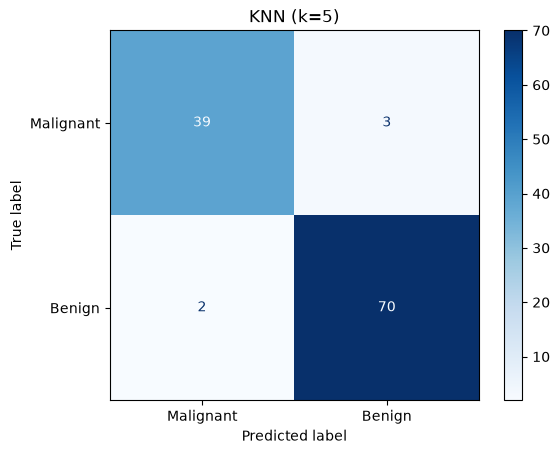

In [4]:
from sklearn.neighbors import KNeighborsClassifier
model = Pipeline([('scale', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5))])
evaluate('KNN (k=5)', model)
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks = list(range(1, 16))
scores = []


In [5]:
for k in ks:
    pipe = Pipeline([('scale', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=k))])
    scores.append(cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy').mean())


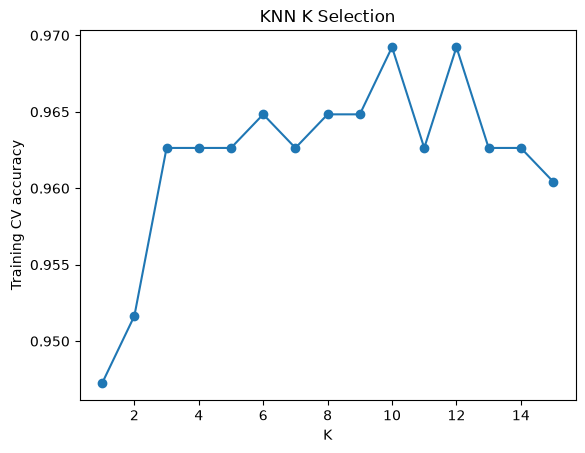

Best CV K: 10


In [6]:
plt.plot(ks, scores, marker='o')
plt.xlabel('K')
plt.ylabel('Training CV accuracy')
plt.title('KNN K Selection')
plt.show()
print('Best CV K:', ks[int(np.argmax(scores))])
